# Laboratorio #4 — Análisis Exploratorio de Datos (EDA)
**Universidad Técnica Nacional** · Minería de Datos (ISW-911) · III Cuatrimestre 2026

**Integrantes:**
- Nayely Vega
- Xavier Fernández
- Álvaro Víctor
- Maikel Chaves

**Conjunto de datos:** Estadísticas policiales del OIJ, año 2025.
Cada fila es un delito reportado en Costa Rica, con su tipo, fecha, hora, víctima y ubicación.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [2]:
URL = "https://raw.githubusercontent.com/xaviferzun/lab4-mineria/main/data/estadisticas_oij_2025.csv"

# Nombres correctos de las 12 columnas (al encabezado original le falta "Hora")
COLUMNAS = ["Delito", "SubDelito", "Fecha", "Hora", "Victima", "SubVictima",
            "Edad", "Sexo", "Nacionalidad", "Provincia", "Canton", "Distrito"]

def unir_nacionalidad(campos):
    # La fila llega con 13 campos: se juntan otra vez los campos 9 y 10 (la nacionalidad partida)
    return campos[:8] + [campos[8] + "," + campos[9]] + campos[10:]

df = pd.read_csv(URL, header=0, names=COLUMNAS,
                 engine="python", on_bad_lines=unir_nacionalidad)

print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (41071, 12)


,Delito,SubDelito,Fecha,Hora,Victima,SubVictima,Edad,Sexo,Nacionalidad,Provincia,Canton,Distrito
0,ASALTO,ARMA BLANCA,2025-01-03,18:00:00 - 20:59:59,VEHICULO,SERVICIO PUBLICO/TAXI LEGAL O PIRATA/AUTOBUS [...,Mayor de edad,HOMBRE,NICARAGUA,SAN JOSE,SAN JOSE,NaN
1,ASALTO,ARMA BLANCA,2025-01-08,06:00:00 - 08:59:59,PERSONA,PEATON [PERSONA],Mayor de edad,MUJER,COSTA RICA,ALAJUELA,ALAJUELA,NaN
2,ASALTO,ARMA BLANCA,2025-01-10,00:00:00 - 02:59:59,PERSONA,PEATON [PERSONA],Mayor de edad,HOMBRE,COSTA RICA,GUANACASTE,CANAS,NaN
3,ASALTO,ARMA BLANCA,2025-01-04,21:00:00 - 23:59:59,PERSONA,PEATON [PERSONA],Mayor de edad,HOMBRE,COSTA RICA,SAN JOSE,GOICOECHEA,NaN
4,ASALTO,ARMA BLANCA,2025-01-10,21:00:00 - 23:59:59,PERSONA,PEATON [PERSONA],Mayor de edad,HOMBRE,NICARAGUA,ALAJUELA,SAN CARLOS,NaN


## 1. Lectura del conjunto de datos desde GitHub (puntos 2 y 3)

El archivo se lee desde la URL *raw* del repositorio público.

**Problemas encontrados al leer el archivo original:**
1. **Comas dentro de un valor:** 4 filas tienen nacionalidades con coma (por ejemplo, `VIRGENES BRITANICAS, ISLAS`), por lo que pandas encuentra 13 columnas en lugar de 12 y da error.
   **Solución:** la función `unir_nacionalidad` vuelve a juntar esos dos campos.
2. **Encabezado incompleto:** al encabezado le falta la columna de la hora, por lo que todos los nombres quedaban corridos un lugar.
   **Solución:** se reemplaza el encabezado con la lista `COLUMNAS`.

Resultado: **41 071 registros y 12 columnas**.

## 2. Características principales del conjunto de datos (punto 4)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41071 entries, 0 to 41070
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Delito        41071 non-null  str    
 1   SubDelito     41071 non-null  str    
 2   Fecha         41071 non-null  str    
 3   Hora          41071 non-null  str    
 4   Victima       41071 non-null  str    
 5   SubVictima    41071 non-null  str    
 6   Edad          41071 non-null  str    
 7   Sexo          41071 non-null  str    
 8   Nacionalidad  41071 non-null  str    
 9   Provincia     41071 non-null  str    
 10  Canton        41071 non-null  str    
 11  Distrito      0 non-null      float64
dtypes: float64(1), str(11)
memory usage: 3.8 MB


**Observaciones de `info()`:**
- El dataset tiene 41 071 registros y 12 columnas.
- 11 columnas son de texto; ninguna variable es numérica.
- `Fecha` se leyó como texto; se convertirá a tipo fecha en el punto 9.
- `Distrito` está completamente vacía (0 valores no nulos); se trata en el punto 6.

In [4]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Delito,41071,6,HURTO,13553,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SubDelito,41071,39,POR DESCUIDO,7578,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fecha,41071,365,2025-11-01,191,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Hora,41071,8,00:00:00 - 02:59:59,7962,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Victima,41071,5,PERSONA,16593,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SubVictima,41071,87,PEATON [PERSONA],10011,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Edad,41071,4,Mayor de edad,34195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sexo,41071,3,HOMBRE,25386,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Nacionalidad,41071,82,COSTA RICA,31763,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Provincia,41071,8,SAN JOSE,16126,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Observaciones de `describe()`:** el delito más frecuente es el **HURTO**, la víctima más común es la **PERSONA** y la provincia con más casos es **SAN JOSE**. Todos los delitos ocurrieron en 2025.

In [5]:
df.nunique().sort_values()

Distrito          0
Sexo              3
Edad              4
Victima           5
Delito            6
Hora              8
Provincia         8
SubDelito        39
Nacionalidad     82
Canton           85
SubVictima       87
Fecha           365
dtype: int64

In [6]:
for columna in ["Delito", "Victima", "Edad", "Sexo", "Provincia", "Hora"]:
    print(f"--- {columna} ---")
    print(df[columna].value_counts(), "\n")

--- Delito ---
Delito
HURTO                13553
ASALTO                9584
ROBO                  7559
ROBO DE VEHICULO      5155
TACHA DE VEHICULO     4350
HOMICIDIO              870
Name: count, dtype: int64 

--- Victima ---
Victima
PERSONA        16593
VEHICULO       11375
VIVIENDA        6675
EDIFICACION     4627
OTROS           1801
Name: count, dtype: int64 

--- Edad ---
Edad
Mayor de edad    34195
Adulto Mayor      3054
Desconocido       2861
Menor de edad      961
Name: count, dtype: int64 

--- Sexo ---
Sexo
HOMBRE         25386
MUJER          13225
DESCONOCIDO     2460
Name: count, dtype: int64 

--- Provincia ---
Provincia
SAN JOSE       16126
ALAJUELA        6365
PUNTARENAS      5044
GUANACASTE      3705
LIMON           3582
HEREDIA         3319
CARTAGO         2927
DESCONOCIDO        3
Name: count, dtype: int64 

--- Hora ---
Hora
00:00:00 - 02:59:59    7962
18:00:00 - 20:59:59    6558
15:00:00 - 17:59:59    5432
21:00:00 - 23:59:59    5353
12:00:00 - 14:59:59    4968
09

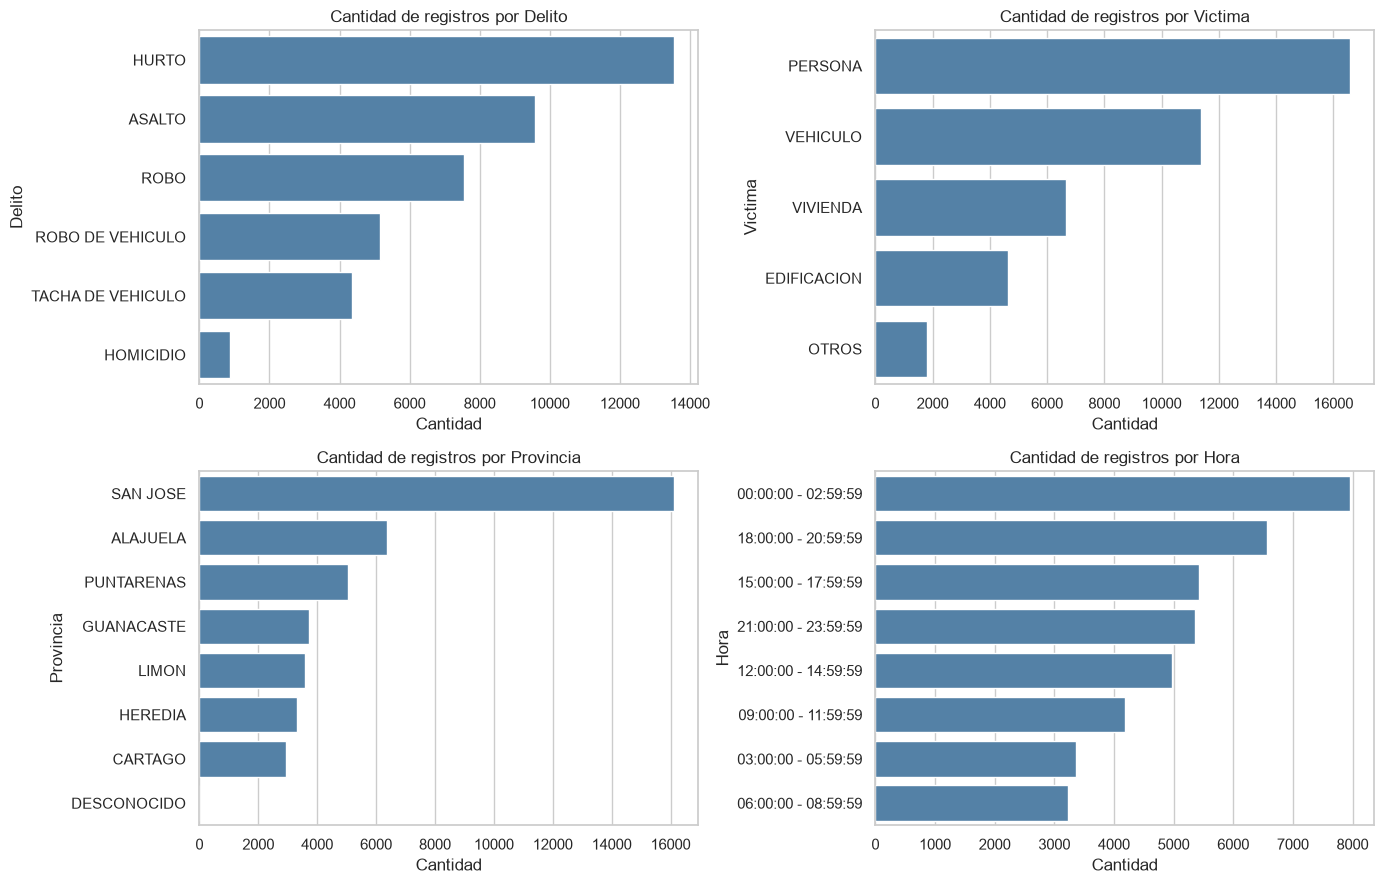

In [7]:
fig, ejes = plt.subplots(2, 2, figsize=(14, 9))
for eje, columna in zip(ejes.flat, ["Delito", "Victima", "Provincia", "Hora"]):
    orden = df[columna].value_counts().index
    sns.countplot(data=df, y=columna, order=orden, ax=eje, color="steelblue")
    eje.set_title(f"Cantidad de registros por {columna}")
    eje.set_xlabel("Cantidad")
plt.tight_layout()
plt.show()

**Observaciones de las variables categóricas:**
- Hay **6 categorías de delito**: el hurto es el más frecuente (13 553) y el homicidio el menos frecuente (870). Las clases están **desbalanceadas**.
- La víctima más común es la persona, seguida del vehículo.
- **San José** concentra cerca del 40 % de los registros.
- La franja horaria con más delitos es la de **00:00 a 02:59**.
- Hay valores **"Desconocido"** en Edad, Sexo, Nacionalidad y Provincia: funcionan como datos faltantes y se tratan en el punto 6.

In [8]:
print("Filas duplicadas:", df.duplicated().sum())

Filas duplicadas: 2812


## 3. Nombres de las columnas en español (punto 5)

Los nombres originales venían desalineados, sin tildes y sin un formato uniforme. Se renombran con nombres descriptivos en español, en minúscula y sin espacios.

In [9]:
NOMBRES_ES = {
    "Delito": "delito",
    "SubDelito": "subdelito",
    "Fecha": "fecha",
    "Hora": "rango_hora",
    "Victima": "tipo_victima",
    "SubVictima": "subtipo_victima",
    "Edad": "grupo_edad",
    "Sexo": "sexo",
    "Nacionalidad": "nacionalidad",
    "Provincia": "provincia",
    "Canton": "canton",
    "Distrito": "distrito",
}
df = df.rename(columns=NOMBRES_ES)
df.columns.tolist()

['delito',
 'subdelito',
 'fecha',
 'rango_hora',
 'tipo_victima',
 'subtipo_victima',
 'grupo_edad',
 'sexo',
 'nacionalidad',
 'provincia',
 'canton',
 'distrito']

## 4. Identificación de valores nulos (punto 6)

Se analizarán los valores faltantes del conjunto de datos para identificar las columnas que presentan información incompleta. También se revisarán los valores registrados como "Desconocido", ya que pueden representar datos faltantes.

In [10]:
# Cantidad de valores nulos por columna
nulos = df.isnull().sum()

# Porcentaje de valores nulos
porcentaje_nulos = (nulos / len(df)) * 100

# Mostrar resultados
resultado_nulos = pd.DataFrame({
    "Valores nulos": nulos,
    "Porcentaje (%)": porcentaje_nulos.round(2)
})

print(resultado_nulos)

                 Valores nulos  Porcentaje (%)
delito                       0             0.0
subdelito                    0             0.0
fecha                        0             0.0
rango_hora                   0             0.0
tipo_victima                 0             0.0
subtipo_victima              0             0.0
grupo_edad                   0             0.0
sexo                         0             0.0
nacionalidad                 0             0.0
provincia                    0             0.0
canton                       0             0.0
distrito                 41071           100.0


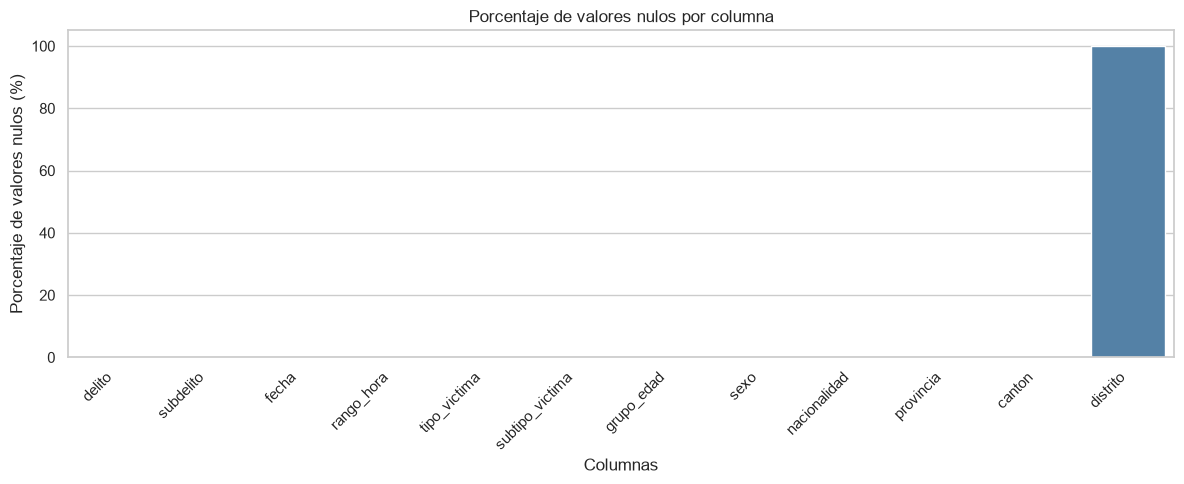

In [11]:
# Gráfico de porcentaje de valores nulos
plt.figure(figsize=(12, 5))

sns.barplot(
    x=resultado_nulos.index,
    y=resultado_nulos["Porcentaje (%)"],
    color="steelblue"
)

plt.title("Porcentaje de valores nulos por columna")
plt.xlabel("Columnas")
plt.ylabel("Porcentaje de valores nulos (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Análisis de los resultados

Al revisar los 41 071 registros, se encontró que la columna `distrito` está completamente vacía, con un 100 % de valores nulos.

Las demás columnas no presentan valores nulos directamente. Sin embargo, existen registros con el valor "Desconocido", que pueden representar información faltante.

Por esta razón, se recomienda eliminar la columna `distrito`, ya que no aporta información al análisis, y revisar los valores desconocidos antes de realizar la imputación.

In [12]:
# Identificar valores registrados como "Desconocido"
columnas_revisar = ["grupo_edad", "sexo", "nacionalidad", "provincia"]

for columna in columnas_revisar:
    cantidad = df[columna].astype(str).str.strip().str.upper().eq("DESCONOCIDO").sum()
    porcentaje = (cantidad / len(df)) * 100

    print(f"{columna}: {cantidad} valores desconocidos ({porcentaje:.2f}%)")

grupo_edad: 2861 valores desconocidos (6.97%)
sexo: 2460 valores desconocidos (5.99%)
nacionalidad: 2722 valores desconocidos (6.63%)
provincia: 3 valores desconocidos (0.01%)


### Identificación de valores desconocidos

Además de los valores nulos, se encontraron registros con el valor "Desconocido" en cuatro columnas:

- Grupo de edad: 2 861 registros (6,97 %).
- Sexo: 2 460 registros (5,99 %).
- Nacionalidad: 2 722 registros (6,63 %).
- Provincia: 3 registros (0,01 %).

Estos valores representan información no especificada y deben considerarse durante el proceso de limpieza.

En el punto 8 se evaluará su tratamiento mediante funciones de imputación. También se eliminará la columna `distrito`, debido a que está completamente vacía.

## 5. Identificación de valores atípicos (punto 7)

Se analizará la cantidad de delitos registrados por día para identificar posibles valores atípicos. Como el conjunto de datos contiene principalmente variables categóricas, primero se calculará una variable numérica a partir de la fecha de cada delito.

Se utilizará el método del rango intercuartílico (IQR) y un diagrama de caja para identificar los días con cantidades de delitos fuera del comportamiento habitual.

In [13]:
# Contar la cantidad de delitos registrados por fecha
conteo_diario = df.groupby("fecha").size()

# Crear una columna con el total de delitos de cada día
df["delitos_dia"] = df["fecha"].map(conteo_diario)

# Mostrar las estadísticas de la nueva variable
print(df["delitos_dia"].describe())

count    41071.000000
mean       114.856931
std         17.053041
min         72.000000
25%        103.000000
50%        113.000000
75%        124.000000
max        191.000000
Name: delitos_dia, dtype: float64


In [14]:
# Calcular los cuartiles utilizando los conteos diarios
Q1 = conteo_diario.quantile(0.25)
Q3 = conteo_diario.quantile(0.75)

# Calcular el rango intercuartilico
IQR = Q3 - Q1

# Establecer los limites para detectar valores atipicos
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# Identificar los dias con valores atipicos
atipicos = conteo_diario[
    (conteo_diario < limite_inferior) |
    (conteo_diario > limite_superior)
]

print("Primer cuartil:", Q1)
print("Tercer cuartil:", Q3)
print("Rango intercuartilico:", IQR)
print("Limite inferior:", limite_inferior)
print("Limite superior:", limite_superior)
print("Cantidad de dias atipicos:", len(atipicos))
print("\nDias con valores atipicos:")
print(atipicos)

Primer cuartil: 101.0
Tercer cuartil: 121.0
Rango intercuartilico: 20.0
Limite inferior: 71.0
Limite superior: 151.0
Cantidad de dias atipicos: 7

Dias con valores atipicos:
fecha
2025-02-01    166
2025-02-08    159
2025-03-01    174
2025-05-28    155
2025-11-01    191
2025-11-02    152
2025-12-20    166
dtype: int64


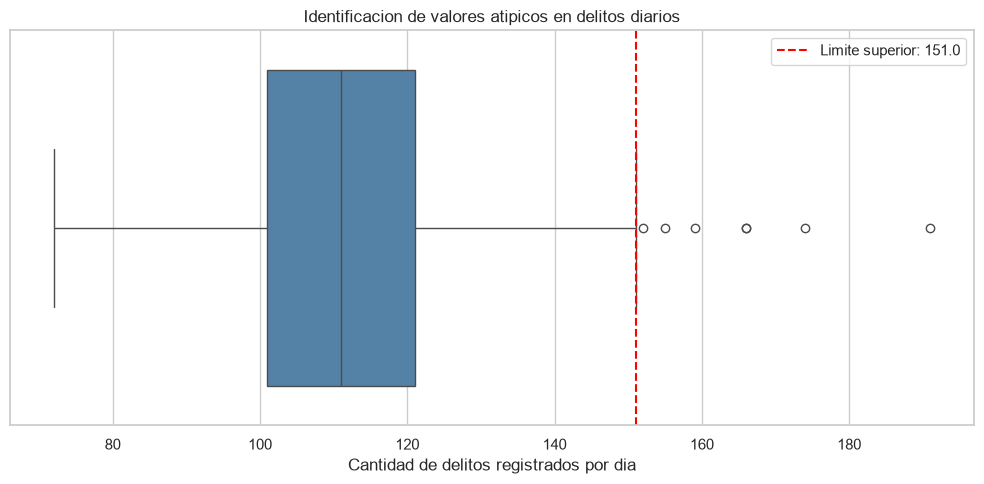

In [15]:
# Diagrama de caja para identificar valores atipicos
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=conteo_diario,
    color="steelblue"
)

plt.axvline(
    limite_superior,
    color="red",
    linestyle="--",
    label=f"Limite superior: {limite_superior}"
)

plt.title("Identificacion de valores atipicos en delitos diarios")
plt.xlabel("Cantidad de delitos registrados por dia")
plt.legend()
plt.tight_layout()
plt.show()

### Análisis de los valores atípicos

Se utilizó el método del rango intercuartílico (IQR) para analizar la cantidad de delitos registrados diariamente durante 2025.

Se obtuvo un límite inferior de 71 y un límite superior de 151 delitos por día.

Se identificaron 7 días con valores atípicos, todos superiores al límite establecido. El día con mayor cantidad de registros fue el 1 de noviembre de 2025, con 191 delitos.

Estos valores no necesariamente representan errores, ya que pueden corresponder a variaciones reales en la cantidad de delitos reportados. Por esta razón, se conservarán inicialmente y se evaluará su tratamiento en el punto 8.

## 6. Tratamiento de valores faltantes e imputación (punto 8)

En esta etapa se realizará la limpieza de los datos faltantes identificados anteriormente.

La columna `distrito` será eliminada porque contiene un 100 % de valores nulos. Además, se crearán funciones para tratar los valores registrados como "Desconocido" en las variables categóricas.

Para la imputación se utilizará la moda, que corresponde al valor más frecuente de cada columna.

In [16]:
# Funcion para eliminar columnas completamente vacias
def eliminar_columnas_vacias(datos):
    columnas_vacias = datos.columns[datos.isnull().all()].tolist()

    datos = datos.drop(columns=columnas_vacias)

    print("Columnas eliminadas:", columnas_vacias)

    return datos

# Aplicar la funcion
df = eliminar_columnas_vacias(df)

# Verificar las columnas restantes
print("Cantidad de columnas:", len(df.columns))
print(df.columns.tolist())

Columnas eliminadas: ['distrito']
Cantidad de columnas: 12
['delito', 'subdelito', 'fecha', 'rango_hora', 'tipo_victima', 'subtipo_victima', 'grupo_edad', 'sexo', 'nacionalidad', 'provincia', 'canton', 'delitos_dia']


In [17]:
# Funcion para imputar valores desconocidos con la moda
def imputar_desconocidos(datos, columnas):
    for columna in columnas:
        # Identificar los valores desconocidos
        mascara = (
            datos[columna].astype(str)
            .str.strip()
            .str.upper()
            .eq("DESCONOCIDO")
        )

        # Obtener la moda sin contar los desconocidos
        moda = datos.loc[~mascara, columna].mode().iloc[0]

        # Reemplazar los valores desconocidos
        datos.loc[mascara, columna] = moda

        print(f"{columna}: {mascara.sum()} valores imputados con '{moda}'")

    return datos

# Columnas que necesitan imputacion
columnas_imputar = [
    "grupo_edad",
    "sexo",
    "nacionalidad",
    "provincia"
]

# Aplicar la funcion
df = imputar_desconocidos(df, columnas_imputar)

grupo_edad: 2861 valores imputados con 'Mayor de edad'
sexo: 2460 valores imputados con 'HOMBRE'
nacionalidad: 2722 valores imputados con 'COSTA RICA'
provincia: 3 valores imputados con 'SAN JOSE'


### Justificación de la imputación

Se utilizó la moda para reemplazar los valores "Desconocido" en las columnas `grupo_edad`, `sexo`, `nacionalidad` y `provincia`.

Este método se seleccionó porque las variables son categóricas y no es posible calcular un promedio numérico para ellas.

La imputación permite trabajar con un conjunto de datos más completo sin eliminar los registros. Sin embargo, puede aumentar la frecuencia de las categorías predominantes, por lo que los resultados deben interpretarse considerando esta limitación.

In [18]:
# Verificar valores nulos después de la limpieza
print("Valores nulos restantes:")
print(df.isnull().sum())

# Verificar valores desconocidos
print("\nValores desconocidos restantes:")

for columna in columnas_imputar:
    cantidad = (
        df[columna].astype(str)
        .str.strip()
        .str.upper()
        .eq("DESCONOCIDO")
        .sum()
    )
    print(f"{columna}: {cantidad}")

# Verificar dimensiones finales
print("\nDimensiones del dataset:", df.shape)

Valores nulos restantes:
delito             0
subdelito          0
fecha              0
rango_hora         0
tipo_victima       0
subtipo_victima    0
grupo_edad         0
sexo               0
nacionalidad       0
provincia          0
canton             0
delitos_dia        0
dtype: int64

Valores desconocidos restantes:
grupo_edad: 0
sexo: 0
nacionalidad: 0
provincia: 0

Dimensiones del dataset: (41071, 12)


### Resultado final de la limpieza

Después de aplicar las funciones de limpieza e imputación, el conjunto de datos conserva los 41 071 registros originales y contiene 12 columnas.

Se eliminó la columna `distrito` porque estaba completamente vacía y se reemplazaron los valores "Desconocido" de cuatro variables categóricas mediante la moda.

La verificación final confirmó que no quedan valores nulos ni registros "Desconocido" en las columnas tratadas.

Además, se conservaron los registros duplicados, ya que no existe un identificador único que permita determinar si corresponden al mismo delito. Los valores atípicos también se conservaron inicialmente, debido a que podrían representar variaciones reales.

### Creación de variables numéricas para el análisis

Se crearán tres variables a partir de la fecha y el rango horario de los delitos: mes, día de la semana y hora de inicio.

Estas variables permitirán analizar patrones temporales y facilitarán los procesos de transformación y estandarización de los siguientes apartados.

In [19]:
# Extraer variables numericas de la fecha
fechas = pd.to_datetime(df["fecha"], format="%Y-%m-%d")

df["mes"] = fechas.dt.month
df["dia_semana"] = fechas.dt.day_of_week

# Extraer la hora de inicio del rango horario
df["hora_inicio"] = df["rango_hora"].str[:2].astype(int)

# Verificar las nuevas columnas
print(df[["fecha", "mes", "dia_semana",
          "rango_hora", "hora_inicio"]].head())

print("\nDimensiones del dataset:", df.shape)

        fecha  mes  dia_semana           rango_hora  hora_inicio
0  2025-01-03    1           4  18:00:00 - 20:59:59           18
1  2025-01-08    1           2  06:00:00 - 08:59:59            6
2  2025-01-10    1           4  00:00:00 - 02:59:59            0
3  2025-01-04    1           5  21:00:00 - 23:59:59           21
4  2025-01-10    1           4  21:00:00 - 23:59:59           21

Dimensiones del dataset: (41071, 15)
